# 10 | Zwei Varianten unter denselben Bedingungen vergleichen

**Lernziele:** Differenzen als eigene Zielgroesse auswerten; gleiche
Nachfrage fuer beide Varianten verwenden; die Unsicherheit passend berechnen.
**Vorwissen:** Listen, Mittelwert, Standardfehler und Intervall aus 02-09.
**Zeit:** gefuehrte Demo und zwei Aufgaben zu je 15 Minuten.
Alle Basiszellen sind ausfuehrbar; eigene Antworten in neue Zellen schreiben.
Erfundene Kosten in Euro pro Tag: A = 20 + 4 * Nachfrage,
B = 30 + 3 * Nachfrage. Keine realen Tarif- oder Unternehmensdaten.
**Vorzeichen immer B minus A:** Negativ bedeutet hier niedrigere Kosten von B.
**Arbeitsweg:** Die fertigen Hilfsfunktionen einmal ausfuehren. Pflicht
sind Paarzuordnung, Vorzeichen und Ergebnisdeutung, nicht die Implementierung
des Welch-Verfahrens oder der t-Intervalle. Neue Aufrufe in eigene Zellen setzen.

In [1]:
from random import Random
import math
from statistics import mean, stdev, variance

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t

plt.rcParams.update({"font.size": 13})


def kosten_a(nachfrage):
    return 20 + 4 * nachfrage


def kosten_b(nachfrage):
    return 30 + 3 * nachfrage


def paardifferenzen(werte_a, werte_b):
    if len(werte_a) == 0 or len(werte_a) != len(werte_b):
        raise ValueError("Gleich viele, nichtleere Werte fuer A und B erforderlich")
    if not all(math.isfinite(wert) for wert in [*werte_a, *werte_b]):
        raise ValueError("Alle Werte muessen endlich sein")
    return [wert_b - wert_a for wert_a, wert_b in zip(werte_a, werte_b)]


nachfragefolge = [2, 4, 8, 12]
kostenfolge_a = [kosten_a(nachfrage) for nachfrage in nachfragefolge]
kostenfolge_b = [kosten_b(nachfrage) for nachfrage in nachfragefolge]
for tag, nachfrage, wert_a, wert_b in zip(range(1, 5), nachfragefolge, kostenfolge_a, kostenfolge_b):
    print(f"Tag {tag}: Nachfrage {nachfrage:2}, A {wert_a:2}, B {wert_b:2}, B-A {wert_b-wert_a:3}")
print("Mittlere Differenz:", mean(paardifferenzen(kostenfolge_a, kostenfolge_b)))

Tag 1: Nachfrage  2, A 28, B 36, B-A   8
Tag 2: Nachfrage  4, A 36, B 42, B-A   6
Tag 3: Nachfrage  8, A 52, B 54, B-A   2
Tag 4: Nachfrage 12, A 68, B 66, B-A  -2
Mittlere Differenz: 3.5


## 1. Die Paare bleiben zusammen

Die Einheit der Auswertung ist ein Tag mit beiden Kosten, nicht eine
ungeordnete Sammlung aller Kosten. Erst B-A je Tag bilden, dann mitteln.
Bei gleichen Paarzahlen ist dieser Mittelwert auch Mittel(B)-Mittel(A).
Fuer den Standardfehler braucht man jedoch die Streuung der **Differenzen**.

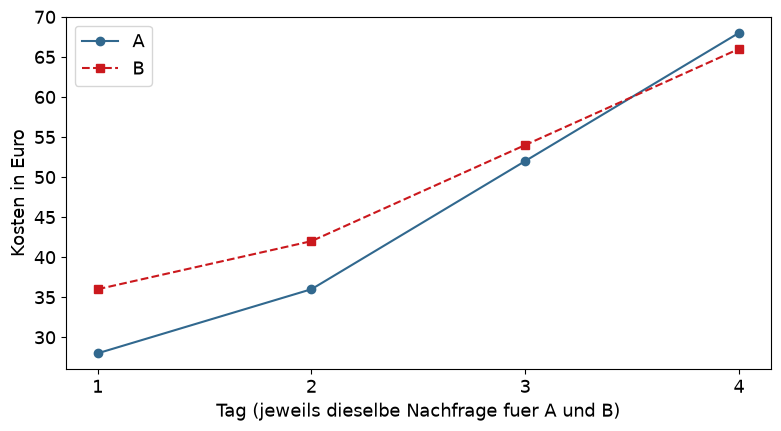

In [2]:
figur, achse = plt.subplots(figsize=(8, 4.5))
achse.plot(range(1, 5), kostenfolge_a, "o-", label="A", color="#31688e")
achse.plot(range(1, 5), kostenfolge_b, "s--", label="B", color="#cb181d")
achse.set(xlabel="Tag (jeweils dieselbe Nachfrage fuer A und B)", ylabel="Kosten in Euro", xticks=range(1, 5))
achse.legend()
figur.tight_layout()
plt.show()

In [3]:
def differenzbericht(werte_a, werte_b, gepaart=True):
    if min(len(werte_a), len(werte_b)) < 2:
        raise ValueError("Mindestens zwei Werte pro Variante erforderlich")
    if not all(math.isfinite(wert) for wert in [*werte_a, *werte_b]):
        raise ValueError("Alle Werte muessen endlich sein")
    if gepaart:
        differenzen = paardifferenzen(werte_a, werte_b)
        standardfehler = stdev(differenzen) / math.sqrt(len(differenzen))
        freiheitsgrade = len(differenzen) - 1
    else:
        varianz_a = variance(werte_a) / len(werte_a)
        varianz_b = variance(werte_b) / len(werte_b)
        standardfehler = math.sqrt(varianz_a + varianz_b)
        if standardfehler > 0:
            freiheitsgrade = (varianz_a + varianz_b) ** 2 / (
                varianz_a ** 2 / (len(werte_a) - 1) + varianz_b ** 2 / (len(werte_b) - 1)
            )
        else:
            freiheitsgrade = min(len(werte_a), len(werte_b)) - 1
    differenz = mean(werte_b) - mean(werte_a)
    halbbreite = float(t.ppf(0.975, freiheitsgrade)) * standardfehler
    return {
        "differenz": differenz, "standardfehler": standardfehler,
        "unten": differenz - halbbreite, "oben": differenz + halbbreite,
        "anzahl_a": len(werte_a), "anzahl_b": len(werte_b),
    }


rechenprobe = differenzbericht(kostenfolge_a, kostenfolge_b)
print("Rechenprobe mit festen Werten, mittlere Differenz:", rechenprobe["differenz"])

Rechenprobe mit festen Werten, mittlere Differenz: 3.5


Gepaarter SE: Stichproben-Standardabweichung der Differenzen geteilt durch
Wurzel der Paarzahl. Fuer unabhaengige Daten addiert der Code stattdessen
die beiden geschaetzten Mittelwertvarianzen (Welch-Verfahren).
Die t-Intervalle sind hier **naeherungsweise 95-Prozent-Intervalle**.
Sie setzen unabhaengige Tage voraus; ein enger Bereich prueft keine Modellannahme.
Ein Bereich, der null einschliesst, beweist nicht die Gleichheit der Varianten.
Identische beobachtete Differenzen ergeben SE null; das allein beweist
bei unbekannten Modellen keine konstante Differenz in der Population.

## 2. Gleiche Nachfrage oder unabhaengige Nachfrage

Erst jetzt ziehen wir zufaellige Tage. Die vier festen Lehrtage oben sind
nur eine Rechenprobe, keine Datengrundlage fuer eine 95%-Intervallaussage.
Modellannahme: Die ganzzahlige Nachfrage ist gleichverteilt von 0 bis 30,
unabhaengig von Tag zu Tag. Ihr Mittelwert ist 15. Damit ist die bekannte
Referenz fuer B-A gleich 10-15 = -5 Euro pro Tag.
Pro Methode werden N Tage je Variante, also **2N Kostenwerte**, ausgewertet.
Gemeinsam: N Nachfrageziehungen; unabhaengig: 2N Nachfrageziehungen.
Gleiche Zahl an Modellauswertungen bedeutet daher nicht identische Rechenzeit.

In [4]:
def kostenvergleich(anzahl, seed, gemeinsam=True):
    if not isinstance(anzahl, int) or anzahl < 2:
        raise ValueError("Mindestens zwei ganze Tage erforderlich")
    strom_a, strom_b = np.random.default_rng(seed).spawn(2)
    nachfragen_a = strom_a.integers(0, 31, size=anzahl).tolist()
    nachfragen_b = nachfragen_a if gemeinsam else strom_b.integers(0, 31, size=anzahl).tolist()
    werte_a = [kosten_a(nachfrage) for nachfrage in nachfragen_a]
    werte_b = [kosten_b(nachfrage) for nachfrage in nachfragen_b]
    return differenzbericht(werte_a, werte_b, gepaart=gemeinsam)


berichte = [kostenvergleich(200, 2026, gemeinsam=gemeinsam) for gemeinsam in [True, False]]
for name, bericht in zip(["Gemeinsame Nachfrage", "Unabhaengige Nachfrage"], berichte):
    print(name, bericht)

Gemeinsame Nachfrage {'differenz': -5.864999999999995, 'standardfehler': 0.6248488259382279, 'unten': -7.097174731476908, 'oben': -4.6328252685230815, 'anzahl_a': 200, 'anzahl_b': 200}
Unabhaengige Nachfrage {'differenz': -6.375, 'standardfehler': 3.144985779421557, 'unten': -12.559167025366893, 'oben': -0.190832974633107, 'anzahl_a': 200, 'anzahl_b': 200}


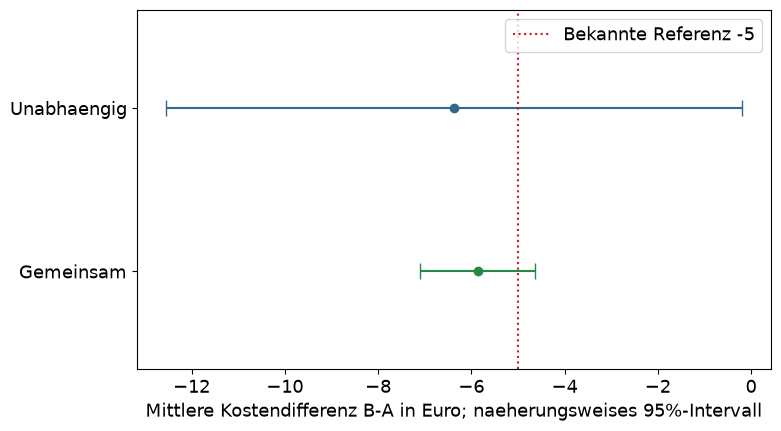

In [5]:
figur, achse = plt.subplots(figsize=(8, 4.5))
for position, bericht in enumerate(berichte):
    achse.errorbar(bericht["differenz"], position, xerr=bericht["oben"] - bericht["differenz"],
                  fmt="o", capsize=6, color=["#238b45", "#31688e"][position])
achse.axvline(-5, color="#cb181d", linestyle=":", label="Bekannte Referenz -5")
achse.set(yticks=[0, 1], yticklabels=["Gemeinsam", "Unabhaengig"], ylim=(-0.6, 1.6),
          xlabel="Mittlere Kostendifferenz B-A in Euro; naeherungsweises 95%-Intervall")
achse.legend(loc="upper right")
figur.tight_layout()
plt.show()

In diesem Modell reagieren beide Kosten gleichgerichtet auf Nachfrage.
Die Kopplung reduziert deshalb die Streuung der Differenz. Fuer jede Variante
einzeln bleibt das Nachfragemodell dasselbe. Die unabhaengige Methode ist
nicht falsch oder systematisch verzerrt; sie ist hier weniger praezise.
Ein einzelner Lauf belegt keinen generellen Gewinn und keine exakte Deckungsrate.

In [6]:
studienseeds = np.random.SeedSequence(2026).spawn(40)
for gemeinsam in [True, False]:
    studie = [kostenvergleich(200, seed, gemeinsam) for seed in studienseeds]
    print("Gemeinsam:", gemeinsam,
          "Streuung der 40 Differenzschaetzungen:", stdev([bericht["differenz"] for bericht in studie]),
          "Mittlerer geschaetzter SE:", mean([bericht["standardfehler"] for bericht in studie]))

Gemeinsam: True Streuung der 40 Differenzschaetzungen: 0.5443233272746864 Mittlerer geschaetzter SE: 0.6353497065163229
Gemeinsam: False Streuung der 40 Differenzschaetzungen: 2.7798427799805974 Mittlerer geschaetzter SE: 3.1685450616145006


## A10.1 | Gleicher Tag, zwei Varianten | 15 Minuten

Verwenden Sie die feste Nachfragefolge [0, 5, 15, 25]. Bilden Sie A, B und
B-A je Tag. Berechnen Sie die mittlere Differenz und erklaeren Sie ihr Vorzeichen.
CR10.1 kann den kurzen Programmierteil ersetzen.
**Hilfe:** A = 20 + 4 * Nachfrage; B = 30 + 3 * Nachfrage.

## A10.2 | Vergleich und Fehlerbalken | 15 Minuten

Rufen Sie `kostenvergleich(200, 42, gemeinsam=True)` und dieselbe Funktion
mit `gemeinsam=False` auf. Vergleichen Sie Schaetzung, SE und Intervall.
Wiederholen Sie mit Seed 43. Welche Aussage bleibt, welche Zahlen aendern sich?
Warum ist ein unabhaengiger Lauf nicht einfach ein falscher Vergleich?
**Hilfe:** Beide Methoden zielen auf -5 Euro. Das Intervall beschreibt die
mittlere Differenz, nicht die Schwankung einzelner Tageskosten.
Vier einzelne Aufrufe reichen; die Hilfsfunktion waehlt die SE-Rechnung.
Notieren Sie `differenz`, `standardfehler`, `unten` und `oben` je Aufruf.
**Leseregel unter dem Modell:** Beide Grenzen negativ sprechen fuer im
Mittel guenstigeres B; beide positiv fuer teureres B. Enthaelt das Intervall
null, ist die Richtung nicht eindeutig abgesichert. Das beweist keine
Gleichheit und sagt nichts ueber die Gueltigkeit der Eingabeannahmen aus.

## Pflichtteil endet hier

- Die Differenz B-A ist die Zielgroesse; ihr Vorzeichen braucht eine Bedeutung.
- Gemeinsame Zufallszahlen brauchen passend zugeordnete Eingaben.
- Der SE muss zur Auswertungseinheit passen: hier Tage mit ihren Differenzen.

**Abschlussfrage:** Warum ist die Streuung von B-A und nicht die aller
einzelnen Kosten die passende Grundlage fuer den gepaarten SE?
**Naechster Termin:** Paare fuer einen Mittelwert statt fuer einen Vergleich bilden.

## Wahlteil | Warum die Kopplung hilft oder schaden kann

Fuer unabhaengige Paare und gleiche Paarzahl gilt
Var(Mittel(B-A)) = (Var(B) + Var(A) - 2 Cov(A,B)) / N.
Positive Kovarianz hilft gegenueber unabhaengigen Eingaben; negative schadet.
Gleiche Zufallszahlen erzwingen kein positives Vorzeichen. Geringe Korrelation
beweist allein keinen Programmfehler. Hier haben die Kosten Koeffizienten
4 und 3: unabhaengiger Varianzfaktor 16+9=25, gepaarter Faktor (3-4)^2=1.
Der theoretische **SE-Faktor** ist deshalb 5, der **Varianzfaktor** 25.

In [7]:
uniformwerte = np.random.default_rng(42).random(5000)
gegenbeispiel_a = uniformwerte.tolist()
gegenbeispiel_b = (1 - uniformwerte).tolist()
print("Negative Korrelation:", float(np.corrcoef(gegenbeispiel_a, gegenbeispiel_b)[0, 1]))
print("Gepaarter SE:", differenzbericht(gegenbeispiel_a, gegenbeispiel_b)["standardfehler"])
print("Theorie: Varianz pro Differenz gemeinsam = 1/3, unabhaengig = 1/6")

Negative Korrelation: -1.0
Gepaarter SE: 0.008160777525465108
Theorie: Varianz pro Differenz gemeinsam = 1/3, unabhaengig = 1/6


## Wahlteil | Synchronisation und Originalbeispiele

Ein gleicher Seed reicht nicht: Zusaetzliche Ziehungen in einer Variante
verschieben die Zuordnung. Im Pflichtbeispiel wird deshalb Nachfrage zuerst
erzeugt und dann fuer beide Kostenregeln verwendet. In groesseren Modellen
benoetigen Ankunft, Bedarf und Service eigene sinnvoll zugeordnete Streams
oder ereignisbezogene Eingaben. Warteschlangen folgen spaeter.

In [8]:
generator_a = Random(7)
generator_b = Random(7)
print("Erste Eingaben gleich:", generator_a.random() == generator_b.random())
zusatz_b = generator_b.random()
print("Nach Zusatzziehung noch gleich:", generator_a.random() == generator_b.random())

originalstrom = np.random.default_rng(42)
eingaben = originalstrom.random(50000)
original_a = np.exp(eingaben)
original_b = original_a + 0.1 * eingaben ** 2
print("KAP3, B-A, Referenz 1/30:", differenzbericht(original_a.tolist(), original_b.tolist()))


def marktvergleich(anzahl, seed, lage=0, gemeinsam=True):
    if not isinstance(anzahl, int) or anzahl < 2 or not math.isfinite(lage):
        raise ValueError("Mindestens zwei ganze Ziehungen und endliche Lage erforderlich")
    strom_a, strom_b = np.random.default_rng(seed).spawn(2)
    faktor_a = strom_a.normal(lage, 1, anzahl)
    faktor_b = faktor_a if gemeinsam else strom_b.normal(lage, 1, anzahl)
    werte_a = (5 + np.exp(faktor_a)).tolist()
    werte_b = (7 + 0.9 * np.exp(faktor_b)).tolist()
    bericht = differenzbericht(werte_a, werte_b, gepaart=gemeinsam)
    bericht["korrelation"] = float(np.corrcoef(werte_a, werte_b)[0, 1])
    return bericht


for gemeinsam in [True, False]:
    print("UEB3 Markt, B-A:", gemeinsam, marktvergleich(50000, 42, gemeinsam=gemeinsam))

Erste Eingaben gleich: True
Nach Zusatzziehung noch gleich: False
KAP3, B-A, Referenz 1/30: {'differenz': 0.03341917707012332, 'standardfehler': 0.00013322003481147545, 'unten': 0.033158064278915704, 'oben': 0.03368028986133093, 'anzahl_a': 50000, 'anzahl_b': 50000}


UEB3 Markt, B-A: True {'differenz': 1.835835631102663, 'standardfehler': 0.0009673678549021541, 'unten': 1.8339395790480642, 'oben': 1.8377316831572617, 'anzahl_a': 50000, 'anzahl_b': 50000, 'korrelation': 0.9999999999999983}
UEB3 Markt, B-A: False {'differenz': 1.839937070324691, 'standardfehler': 0.012938443072574034, 'unten': 1.8145778766663294, 'oben': 1.8652962639830524, 'anzahl_a': 50000, 'anzahl_b': 50000, 'korrelation': 0.004342371676525053}


Die alte UEB3 definierte **Ersparnis A-B**, also das negative Vorzeichen
unserer **Mehrkosten B-A**. Ihre Referenz bei Lage 0 ist
-2 + 0.1 * exp(0.5). Fuer Ersparnis: Schaetzung negieren und Intervall
[-oben, -unten] bilden. Der Markt-Lagevergleich und das faktorielle Design
aus derselben Originalaufgabe werden in Einheit 15 weitergefuehrt.